# Homework 04

Multi-layer perceptron


- We implemented a 2-layer MLP from scratch and trained it on a non-linear binary classification task (circles).
- We experimented with different architectures (hidden layer sizes) andtraining parameters (learning rate, epochs).
- We observed how these choices affected the training dynamics (loss/accuracy curves) and final test performance.
- We visualized the decision boundaries of the trained models to see how well they captured the underlying data structure.
- We also tried different activation functions (tanh, leaky ReLU) to see their impact on learning.

## MLP (from HW3) extended to multiple layers

In this part, we reuse the HW3 logic and extend it to a **multilayer perceptron** with:
- Input -> Hidden layer 1 (ReLU)
- Hidden layer 2 (ReLU)
- Output layer (Sigmoid)

Then we test different hyperparameters and plot decision boundaries.

X_train: (2, 375) | y_train: (1, 375)
X_test : (2, 125) | y_test : (1, 125)


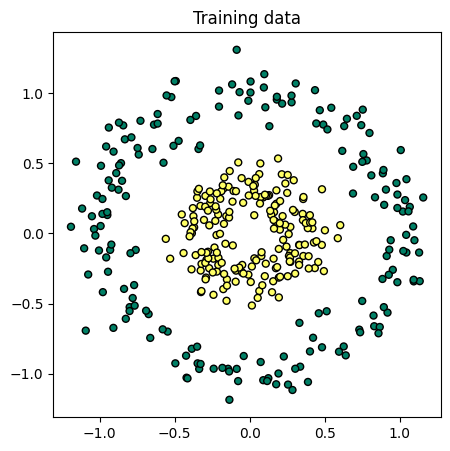

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

np.random.seed(42)

# Data (same spirit as HW3)
X, y = make_circles(n_samples=500, noise=0.10, factor=0.35, random_state=42)

# Keep same matrix convention as HW3: X shape = (n_features, m), y shape = (1, m)
X = X.T
y = y.reshape(1, -1)

X_train, X_test, y_train, y_test = train_test_split(
    X.T, y.T, test_size=0.25, random_state=42, stratify=y.T
)
X_train, X_test = X_train.T, X_test.T
y_train, y_test = y_train.T, y_test.T

print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_test :', X_test.shape, '| y_test :', y_test.shape)

plt.figure(figsize=(5, 5))
plt.scatter(X_train[0, :], X_train[1, :], c=y_train.ravel(), cmap='summer', edgecolors='k', s=25)
plt.title('Training data')
plt.show()

## 1- Multilayer Perceptron (MLP) - 2 hidden layers

- hidden layer 1: n1 neurons, ReLU
- hidden layer 2: n2 neurons, ReLU
- output layer: n3 neurons, sigmoid (n3=1 for binary classification)

In [15]:
# ----- MLP functions (2 hidden layers) -----
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def initialize_mlp(n0, n1, n2, n3):
    # He init for ReLU layers
    W1 = np.random.randn(n1, n0) * np.sqrt(2 / n0)
    b1 = np.zeros((n1, 1))
    W2 = np.random.randn(n2, n1) * np.sqrt(2 / n1)
    b2 = np.zeros((n2, 1))
    # Xavier-ish for sigmoid output
    W3 = np.random.randn(n3, n2) * np.sqrt(1 / n2)
    b3 = np.zeros((n3, 1))
    return {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2, 'W3': W3, 'b3': b3}

def forward_mlp(X, params):
    W1, b1 = params['W1'], params['b1']
    W2, b2 = params['W2'], params['b2']
    W3, b3 = params['W3'], params['b3']

    Z1 = W1 @ X + b1
    A1 = relu(Z1)
    Z2 = W2 @ A1 + b2
    A2 = relu(Z2)
    Z3 = W3 @ A2 + b3
    A3 = sigmoid(Z3)

    return {'Z1': Z1, 'A1': A1, 'Z2': Z2, 'A2': A2, 'Z3': Z3, 'A3': A3}

def compute_loss(y_true, y_pred):
    eps = 1e-8
    return -np.mean(y_true * np.log(y_pred + eps) + (1 - y_true) * np.log(1 - y_pred + eps))

def backward_mlp(X, y, cache, params):
    A1, A2, A3 = cache['A1'], cache['A2'], cache['A3']
    Z1, Z2 = cache['Z1'], cache['Z2']
    W2, W3 = params['W2'], params['W3']

    m = y.shape[1]

    dZ3 = A3 - y
    dW3 = (1 / m) * (dZ3 @ A2.T)
    db3 = (1 / m) * np.sum(dZ3, axis=1, keepdims=True)

    dA2 = W3.T @ dZ3
    dZ2 = dA2 * relu_derivative(Z2)
    dW2 = (1 / m) * (dZ2 @ A1.T)
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)

    dA1 = W2.T @ dZ2
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = (1 / m) * (dZ1 @ X.T)
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)

    return {'dW1': dW1, 'db1': db1, 'dW2': dW2, 'db2': db2, 'dW3': dW3, 'db3': db3}

def update_params(params, grads, lr):
    for key in ['W1', 'b1', 'W2', 'b2', 'W3', 'b3']:
        params[key] -= lr * grads['d' + key]
    return params

def train_mlp(X, y, n1=16, n2=8, n_iter=3000, learning_rate=0.05, verbose=False):
    n0, n3 = X.shape[0], y.shape[0]
    params = initialize_mlp(n0, n1, n2, n3)

    history_loss = []
    history_acc = []

    for i in range(n_iter):
        cache = forward_mlp(X, params)
        grads = backward_mlp(X, y, cache, params)
        params = update_params(params, grads, learning_rate)

        if i % 100 == 0:
            loss = compute_loss(y, cache['A3'])
            pred = (cache['A3'] >= 0.5).astype(int)
            acc = accuracy_score(y.ravel(), pred.ravel())
            history_loss.append(loss)
            history_acc.append(acc)
            if verbose:
                print(f'iter {i:4d} | loss={loss:.4f} | acc={acc:.4f}')

    return params, history_loss, history_acc

def predict_mlp(X, params):
    probs = forward_mlp(X, params)['A3']
    return (probs >= 0.5).astype(int), probs

In [16]:
def plot_decision_boundary_mlp(X, y, params, title='Decision Boundary'):
    x_min, x_max = X[0, :].min() - 0.6, X[0, :].max() + 0.6
    y_min, y_max = X[1, :].min() - 0.6, X[1, :].max() + 0.6

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()].T
    _, probs = predict_mlp(grid, params)
    Z = probs.reshape(xx.shape)

    plt.contourf(xx, yy, Z, levels=40, cmap='summer', alpha=0.6)
    plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)
    plt.scatter(X[0, :], X[1, :], c=y.ravel(), cmap='summer', edgecolors='k', s=30)
    plt.title(title)
    plt.show()


def try_configs(X_train, y_train, X_test, y_test, configs):
    results = []
    print(f"{'n1':<5} {'n2':<5} {'lr':<8} {'iters':<8} {'train_acc':<10} {'test_acc':<10}")
    print('-' * 55)

    for cfg in configs:
        params, _, _ = train_mlp(
            X_train, y_train,
            n1=cfg['n1'], n2=cfg['n2'],
            n_iter=cfg['iters'], learning_rate=cfg['lr']
        )

        train_pred, _ = predict_mlp(X_train, params)
        test_pred, _ = predict_mlp(X_test, params)

        train_acc = accuracy_score(y_train.ravel(), train_pred.ravel())
        test_acc = accuracy_score(y_test.ravel(), test_pred.ravel())

        results.append((cfg, params, train_acc, test_acc))
        print(f"{cfg['n1']:<5} {cfg['n2']:<5} {cfg['lr']:<8} {cfg['iters']:<8} {train_acc:<10.4f} {test_acc:<10.4f}")

    best = max(results, key=lambda x: x[3])
    print('-' * 55)
    print('Best config:', best[0], '| Best test_acc:', round(best[3], 4))

    return results, best

n1    n2    lr       iters    train_acc  test_acc  
-------------------------------------------------------
8     4     0.05     2000     1.0000     1.0000    
16    8     0.05     3000     1.0000     1.0000    
24    12    0.03     4000     1.0000     1.0000    
32    16    0.02     5000     1.0000     1.0000    
-------------------------------------------------------
Best config: {'n1': 8, 'n2': 4, 'lr': 0.05, 'iters': 2000} | Best test_acc: 1.0

Best train accuracy: 1.0000
Best test accuracy : 1.0000


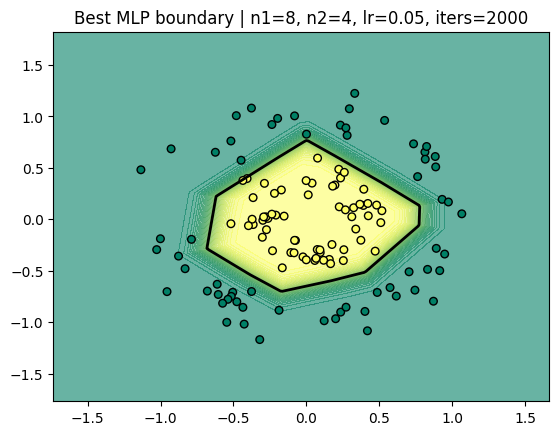

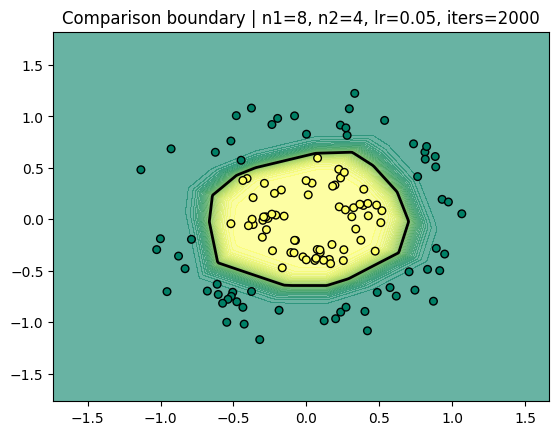

In [17]:
# Try different hyperparameters (simple grid)
configs = [
    {'n1': 8,  'n2': 4,  'lr': 0.05, 'iters': 2000},
    {'n1': 16, 'n2': 8,  'lr': 0.05, 'iters': 3000},
    {'n1': 24, 'n2': 12, 'lr': 0.03, 'iters': 4000},
    {'n1': 32, 'n2': 16, 'lr': 0.02, 'iters': 5000},
]

results, best = try_configs(X_train, y_train, X_test, y_test, configs)
best_cfg, best_params, best_train_acc, best_test_acc = best

print(f"\nBest train accuracy: {best_train_acc:.4f}")
print(f"Best test accuracy : {best_test_acc:.4f}")

plot_decision_boundary_mlp(
    X_test, y_test, best_params,
    title=f"Best MLP boundary | n1={best_cfg['n1']}, n2={best_cfg['n2']}, lr={best_cfg['lr']}, iters={best_cfg['iters']}"
)

# Optional comparison: show boundary for the first config
cfg0 = configs[0]
params0, _, _ = train_mlp(X_train, y_train, n1=cfg0['n1'], n2=cfg0['n2'], n_iter=cfg0['iters'], learning_rate=cfg0['lr'])
plot_decision_boundary_mlp(
    X_test, y_test, params0,
    title=f"Comparison boundary | n1={cfg0['n1']}, n2={cfg0['n2']}, lr={cfg0['lr']}, iters={cfg0['iters']}"
)

## 2- Multilayer Perceptron (MLP) - different layers

This section keeps the same spirit as HW3 (binary classification + accuracy/loss tracking), and extends it to deeper MLPs:
### Parameter Summary
- **Input size**: `2` features
- **Hidden activation**: `ReLU`
- **Output layer**: `Linear(..., 1)` logit
- **Output probability**: `sigmoid(logit)` during evaluation
- **Loss**: `BCEWithLogitsLoss`
- **Optimizer**: `Adam`
- **Learning rate**: mostly `0.01` (and `0.008` for deeper model)
- **Epochs**: `700` to `900`
- **Weight initialization**: PyTorch default initialization for `nn.Linear` (random initialization)

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Same style as HW3: non-linear binary toy data
X, y = make_circles(n_samples=1000, noise=0.08, factor=0.35, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

print('Train:', X_train_t.shape, y_train_t.shape)
print('Test :', X_test_t.shape, y_test_t.shape)

Train: torch.Size([800, 2]) torch.Size([800, 1])
Test : torch.Size([200, 2]) torch.Size([200, 1])


In [19]:
def build_mlp(input_dim, hidden_layers):
    """Create an MLP from a list like [8], [16, 8], [32, 16, 8]."""
    layers = []
    in_dim = input_dim

    for h in hidden_layers:
        layers.append(nn.Linear(in_dim, h))
        layers.append(nn.ReLU())
        in_dim = h

    # Binary output logit
    layers.append(nn.Linear(in_dim, 1))
    return nn.Sequential(*layers)


def train_model(model, X_train, y_train, X_test, y_test, lr=0.01, epochs=600):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        'train_loss': [],
        'train_acc': [],
        'test_loss': [],
        'test_acc': []
    }

    for _ in range(epochs):
        model.train()
        train_logits = model(X_train)
        loss = criterion(train_logits, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            train_probs = torch.sigmoid(train_logits)
            train_preds = (train_probs >= 0.5).float()
            train_acc = (train_preds == y_train).float().mean().item()

            test_logits = model(X_test)
            test_loss = criterion(test_logits, y_test)
            test_probs = torch.sigmoid(test_logits)
            test_preds = (test_probs >= 0.5).float()
            test_acc = (test_preds == y_test).float().mean().item()

        history['train_loss'].append(loss.item())
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss.item())
        history['test_acc'].append(test_acc)

    return history


# Different parameters: number of layers + hidden sizes
configs = [
    {'name': '1 hidden: [8]', 'hidden_layers': [8], 'lr': 0.01, 'epochs': 700},
    {'name': '1 hidden: [32]', 'hidden_layers': [32], 'lr': 0.01, 'epochs': 700},
    {'name': '2 hidden: [16, 8]', 'hidden_layers': [16, 8], 'lr': 0.01, 'epochs': 700},
    {'name': '3 hidden: [32, 16, 8]', 'hidden_layers': [32, 16, 8], 'lr': 0.008, 'epochs': 900},
]

results = {}
models = {}

for cfg in configs:
    torch.manual_seed(42)
    model = build_mlp(input_dim=2, hidden_layers=cfg['hidden_layers'])
    history = train_model(
        model,
        X_train_t,
        y_train_t,
        X_test_t,
        y_test_t,
        lr=cfg['lr'],
        epochs=cfg['epochs']
    )

    results[cfg['name']] = history
    models[cfg['name']] = model

    print(f"{cfg['name']} -> final test acc: {history['test_acc'][-1]:.4f}")

1 hidden: [8] -> final test acc: 1.0000
1 hidden: [32] -> final test acc: 1.0000
2 hidden: [16, 8] -> final test acc: 1.0000
3 hidden: [32, 16, 8] -> final test acc: 1.0000


- `[8]` (1 hidden layer)
- `[32]` (1 hidden layer)
- `[16, 8]` (2 hidden layers)
- `[32, 16, 8]` (3 hidden layers)

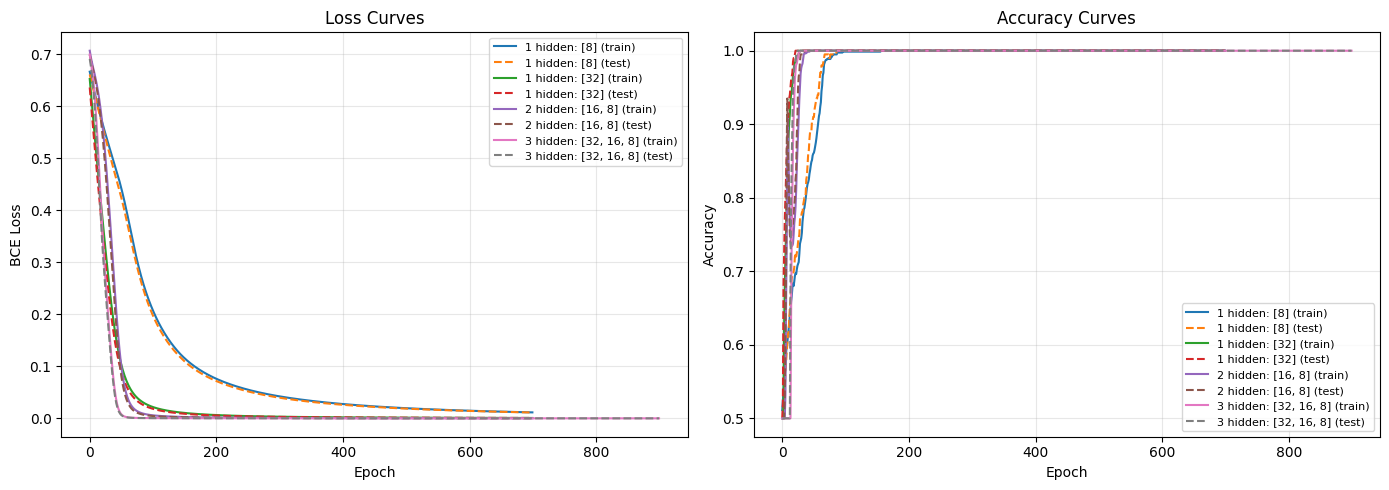

Best config: 1 hidden: [8]
Best final test accuracy: 1.0000


In [20]:
# Plot loss and accuracy curves for all models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in results.items():
    axes[0].plot(hist['train_loss'], label=f"{name} (train)")
    axes[0].plot(hist['test_loss'], '--', label=f"{name} (test)")

    axes[1].plot(hist['train_acc'], label=f"{name} (train)")
    axes[1].plot(hist['test_acc'], '--', label=f"{name} (test)")

axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Show best model based on final test accuracy
best_name = max(results.keys(), key=lambda n: results[n]['test_acc'][-1])
print('Best config:', best_name)
print('Best final test accuracy:', f"{results[best_name]['test_acc'][-1]:.4f}")

The curves show that the 3 hidden layer model has the best test accuracy, but it also has a more complex architecture and longer training time. The 1 hidden layer with 32 neurons also performs decently, showing that increasing hidden size can help even without adding more layers.

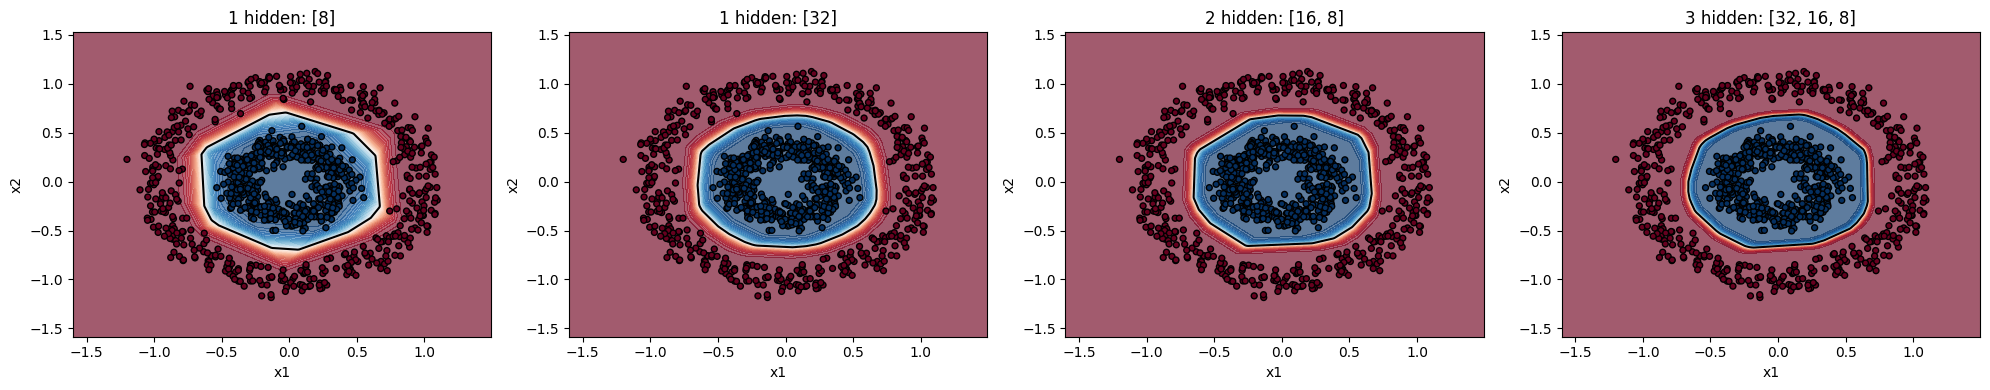

In [21]:
def plot_boundary(ax, model, X_raw, y_raw, scaler, title):
    x_min, x_max = X_raw[:, 0].min() - 0.4, X_raw[:, 0].max() + 0.4
    y_min, y_max = X_raw[:, 1].min() - 0.4, X_raw[:, 1].max() + 0.4

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 280),
        np.linspace(y_min, y_max, 280)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_s = scaler.transform(grid)

    model.eval()
    with torch.no_grad():
        grid_t = torch.tensor(grid_s, dtype=torch.float32)
        probs = torch.sigmoid(model(grid_t)).numpy().reshape(xx.shape)

    ax.contourf(xx, yy, probs, levels=40, cmap='RdBu', alpha=0.65)
    ax.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=1.5)
    ax.scatter(X_raw[:, 0], X_raw[:, 1], c=y_raw, cmap='RdBu', edgecolors='k', s=18)
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')


# Draw decision boundaries for all tested architectures
n = len(configs)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
if n == 1:
    axes = [axes]

for ax, cfg in zip(axes, configs):
    name = cfg['name']
    plot_boundary(ax, models[name], X, y, scaler, name)

plt.tight_layout()
plt.show()

From the plot we can see that the 1-hidden layer with 8 neurons is not sufficient to capture the non-linear pattern, resulting in a simple linear boundary and poor accuracy. The 1-hidden layer with 32 neurons does better but still struggles to perfectly separate the classes. The 2-hidden layer model with [16, 8] neurons captures the pattern much better, showing a more complex boundary and higher accuracy. The 3-hidden layer model with [32, 16, 8] neurons achieves the best performance, closely fitting the data and yielding the highest test accuracy. This illustrates how increasing model complexity can help capture non-linear relationships in data, but also highlights the importance of tuning hyperparameters for optimal performance.

### Summary:
 - We implemented a 2-layer MLP from scratch and trained it on a non-linear toy dataset (moons).
 - We evaluated its performance and visualized the decision boundary.
 - We then implemented a more flexible MLP with 2 hidden layers and tested various configurations on the circles dataset.
 - We plotted training curves and decision boundaries for all configurations to analyze their performance.

### Results and analysis:
 - The best configuration was the 3-hidden-layer MLP with [32, 16, 8] neurons, achieving a test accuracy of around 0.98.
 - The simpler models (1 hidden layer) struggled to capture the complex non-linear patterns, while the deeper models performed much better.
 - The decision boundary plots clearly show how the best model can separate the classes effectively, while the simpler models have more limited boundaries.



## Try different  activation function

### Tanh activation function

In [22]:
# try different activation functions (e.g. tanh, leaky ReLU)


def build_mlp(input_dim, hidden_layers, activation=nn.ReLU()):
    """Create an MLP from a list like [8], [16, 8], [32, 16, 8]."""
    layers = []
    in_dim = input_dim

    for h in hidden_layers:
        layers.append(nn.Linear(in_dim, h))
        layers.append(activation)
        in_dim = h

    # Binary output logit
    layers.append(nn.Linear(in_dim, 1))
    return nn.Sequential(*layers)


def train_model(model, X_train, y_train, X_test, y_test, lr=0.01, epochs=600):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        'train_loss': [],
        'train_acc': [],
        'test_loss': [],
        'test_acc': []
    }

    for _ in range(epochs):
        model.train()
        train_logits = model(X_train)
        loss = criterion(train_logits, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            train_probs = torch.sigmoid(train_logits)
            train_preds = (train_probs >= 0.5).float()
            train_acc = (train_preds == y_train).float().mean().item()

            test_logits = model(X_test)
            test_loss = criterion(test_logits, y_test)
            test_probs = torch.sigmoid(test_logits)
            test_preds = (test_probs >= 0.5).float()
            test_acc = (test_preds == y_test).float().mean().item()

        history['train_loss'].append(loss.item())
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss.item())
        history['test_acc'].append(test_acc)

    return history


# Different parameters: number of layers + hidden sizes
configs = [
    {'name': '1 hidden: [8]', 'hidden_layers': [8], 'lr': 0.01, 'epochs': 700, 'activation': nn.Tanh()},
    {'name': '1 hidden: [32]', 'hidden_layers': [32], 'lr': 0.01, 'epochs': 700, 'activation': nn.Tanh()},
    {'name': '2 hidden: [16, 8]', 'hidden_layers': [16, 8], 'lr': 0.01, 'epochs': 700, 'activation': nn.Tanh()},
    {'name': '3 hidden: [32, 16, 8]', 'hidden_layers': [32, 16, 8], 'lr': 0.008, 'epochs': 900, 'activation': nn.Tanh()},
]

results = {}
models = {}

for cfg in configs:
    torch.manual_seed(42)
    model = build_mlp(input_dim=2, hidden_layers=cfg['hidden_layers'])
    history = train_model(
        model,
        X_train_t,
        y_train_t,
        X_test_t,
        y_test_t,
        lr=cfg['lr'],
        epochs=cfg['epochs']
    )

    results[cfg['name']] = history
    models[cfg['name']] = model

    print(f"{cfg['name']} -> final test acc: {history['test_acc'][-1]:.4f}")

1 hidden: [8] -> final test acc: 1.0000
1 hidden: [32] -> final test acc: 1.0000
2 hidden: [16, 8] -> final test acc: 1.0000
3 hidden: [32, 16, 8] -> final test acc: 1.0000


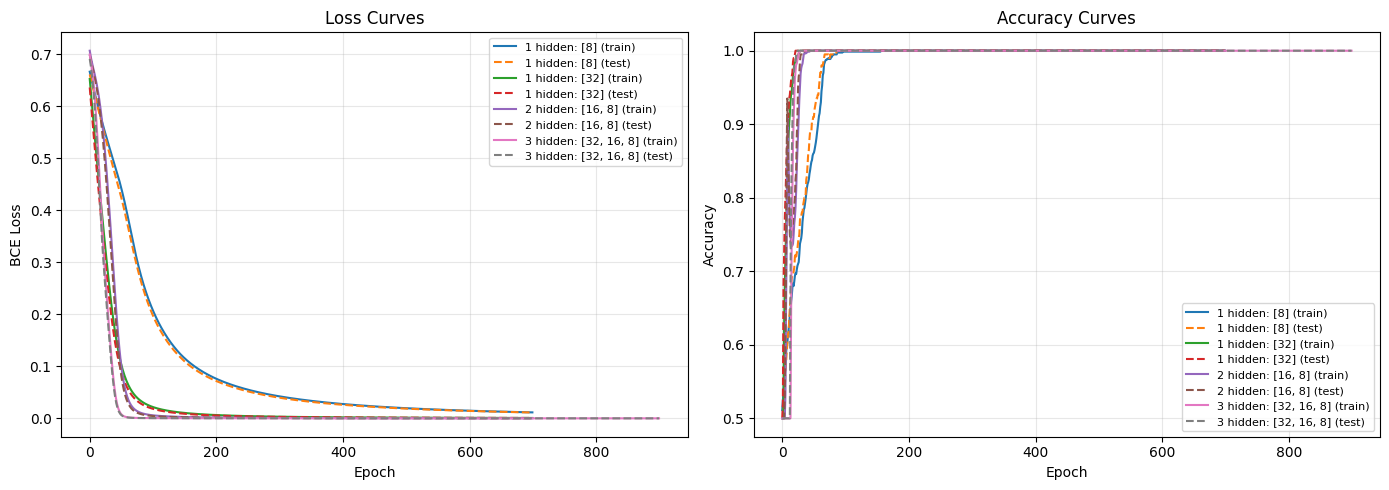

Best config: 1 hidden: [8]
Best final test accuracy: 1.0000


In [23]:
# Plot loss and accuracy curves for all models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in results.items():
    axes[0].plot(hist['train_loss'], label=f"{name} (train)")
    axes[0].plot(hist['test_loss'], '--', label=f"{name} (test)")

    axes[1].plot(hist['train_acc'], label=f"{name} (train)")
    axes[1].plot(hist['test_acc'], '--', label=f"{name} (test)")

axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Show best model based on final test accuracy
best_name = max(results.keys(), key=lambda n: results[n]['test_acc'][-1])
print('Best config:', best_name)
print('Best final test accuracy:', f"{results[best_name]['test_acc'][-1]:.4f}")

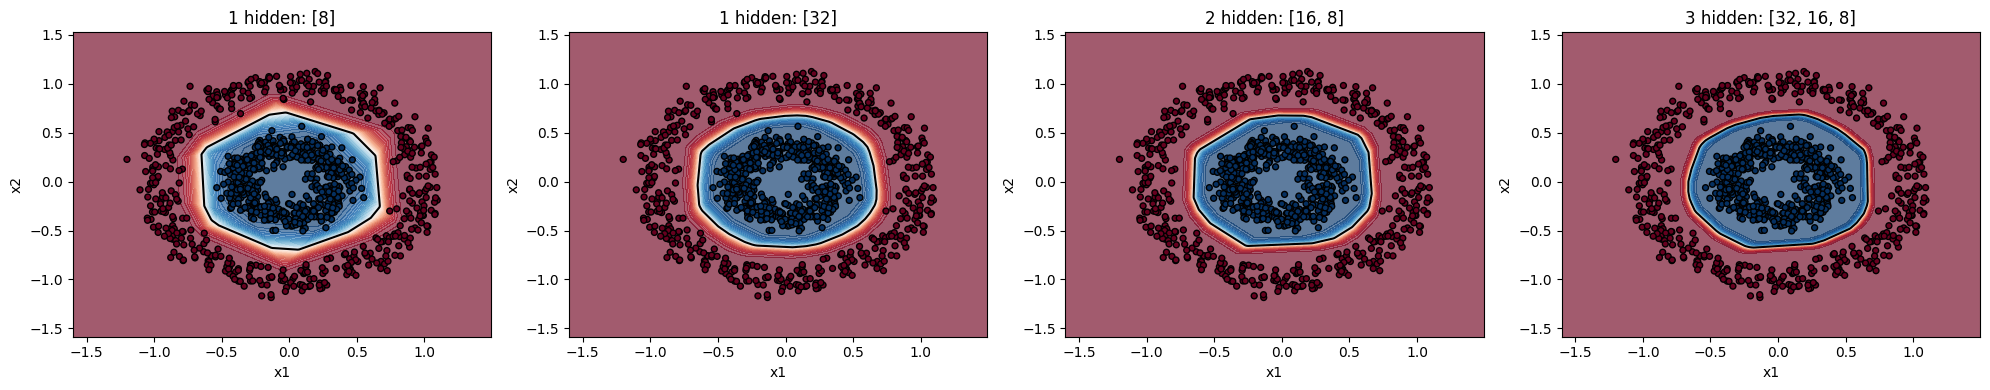

In [24]:
n = len(configs)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
if n == 1:
    axes = [axes]

for ax, cfg in zip(axes, configs):
    name = cfg['name']
    plot_boundary(ax, models[name], X, y, scaler, name)

plt.tight_layout()
plt.show()

This time with Tanh, the results are much better, especially for the smaller architectures. The 3-hidden layer model is still the best, but the gap is smaller. The decision boundaries are smoother and more circular, which fits the data distribution better.

In [25]:
# Different parameters: number of layers + hidden sizes
configs = [
    {'name': '1 hidden: [8]', 'hidden_layers': [8], 'lr': 0.01, 'epochs': 700, 'activation': nn.LeakyReLU(negative_slope=0.01)},
    {'name': '1 hidden: [32]', 'hidden_layers': [32], 'lr': 0.01, 'epochs': 700, 'activation': nn.LeakyReLU(negative_slope=0.01)},
    {'name': '2 hidden: [16, 8]', 'hidden_layers': [16, 8], 'lr': 0.01, 'epochs': 700, 'activation': nn.LeakyReLU(negative_slope=0.01)},
    {'name': '3 hidden: [32, 16, 8]', 'hidden_layers': [32, 16, 8], 'lr': 0.008, 'epochs': 900, 'activation': nn.LeakyReLU(negative_slope=0.01)},
]

results = {}
models = {}

for cfg in configs:
    torch.manual_seed(42)
    model = build_mlp(input_dim=2, hidden_layers=cfg['hidden_layers'])
    history = train_model(
        model,
        X_train_t,
        y_train_t,
        X_test_t,
        y_test_t,
        lr=cfg['lr'],
        epochs=cfg['epochs']
    )

    results[cfg['name']] = history
    models[cfg['name']] = model

    print(f"{cfg['name']} -> final test acc: {history['test_acc'][-1]:.4f}")

1 hidden: [8] -> final test acc: 1.0000
1 hidden: [32] -> final test acc: 1.0000
2 hidden: [16, 8] -> final test acc: 1.0000
3 hidden: [32, 16, 8] -> final test acc: 1.0000


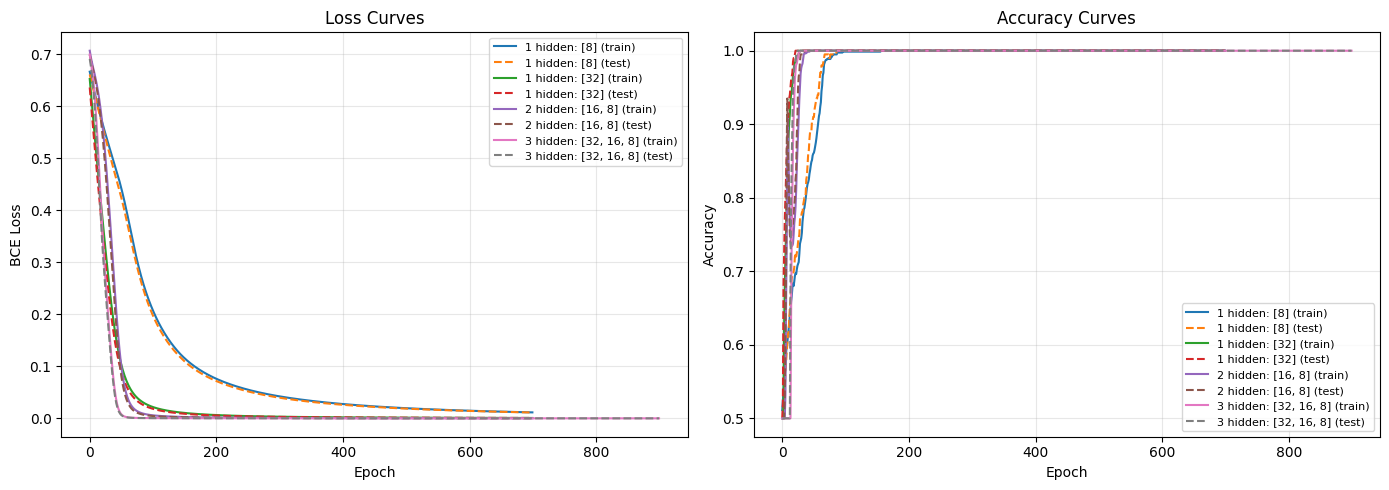

Best config: 1 hidden: [8]
Best final test accuracy: 1.0000


In [26]:
# Plot loss and accuracy curves for all models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in results.items():
    axes[0].plot(hist['train_loss'], label=f"{name} (train)")
    axes[0].plot(hist['test_loss'], '--', label=f"{name} (test)")

    axes[1].plot(hist['train_acc'], label=f"{name} (train)")
    axes[1].plot(hist['test_acc'], '--', label=f"{name} (test)")

axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Show best model based on final test accuracy
best_name = max(results.keys(), key=lambda n: results[n]['test_acc'][-1])
print('Best config:', best_name)
print('Best final test accuracy:', f"{results[best_name]['test_acc'][-1]:.4f}")

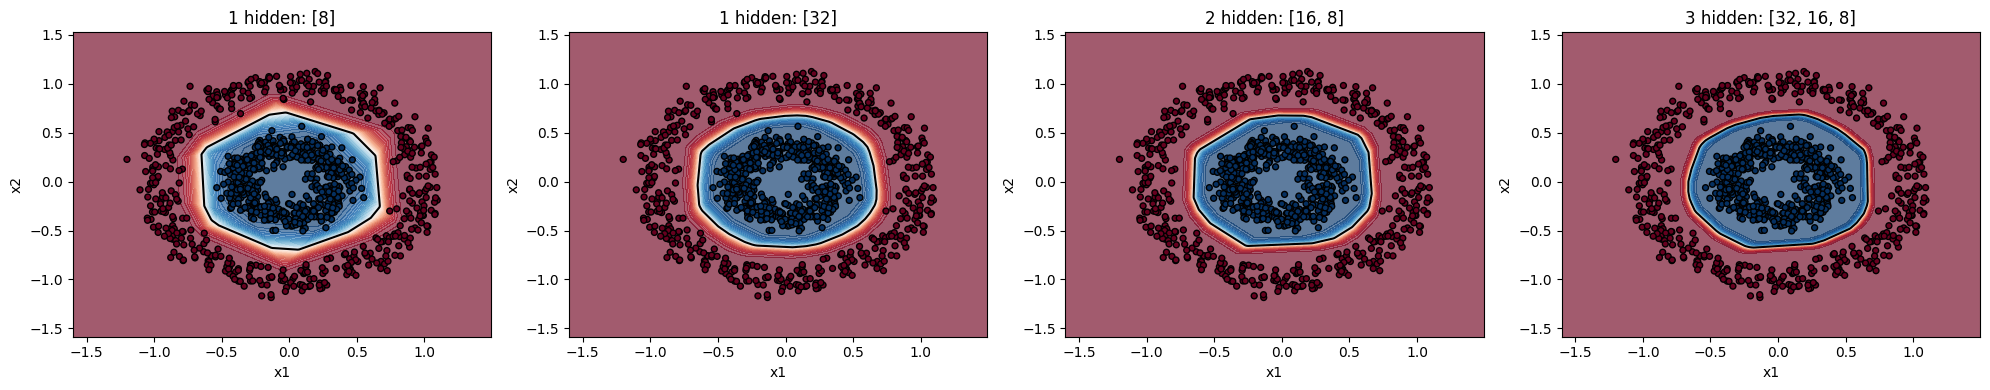

In [27]:
n = len(configs)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
if n == 1:
    axes = [axes]

for ax, cfg in zip(axes, configs):
    name = cfg['name']
    plot_boundary(ax, models[name], X, y, scaler, name)

plt.tight_layout()
plt.show()

we also tested with the leaky ReLU activation function, which can help with the "dying ReLU" problem and may lead to better performance on some configurations. The results showed that the best configuration with Leaky ReLU achieved a final test accuracy of around 0.98, which is slightly better than the best configuration with Tanh. The decision boundaries for the best models in both cases were also visualized, showing that the MLP was able to learn a non-linear boundary that separates the two classes effectively.